In [ ]:
# --- project bootstrap ---
# common/ holds the shared modules (geom_utils, mosaic_utils*).
import sys, pathlib
_common = str(pathlib.Path.cwd().parent / "common")
if _common not in sys.path:
    sys.path.insert(0, _common)
# -------------------------

In [1]:
%matplotlib inline  
from astropy.coordinates import EarthLocation, SkyCoord, AltAz 

from lsst.afw.math import binImage
from lsst.daf.butler import Butler
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm, trange
from lsst.summit.utils.utils import getCameraFromInstrumentName
from lsst.afw.cameraGeom import FOCAL_PLANE

from photutils.segmentation import detect_sources, detect_threshold
from photutils.utils import circular_footprint
from astropy.convolution import convolve
from photutils.segmentation import make_2dgaussian_kernel
import lsst.summit.utils.plotting as splot
from lsst.utils.plotting import make_figure
from scipy.ndimage import gaussian_filter
import geom_utils as gu
from astropy import units as u


# %matplotlib inline 
# %matplotlib widget


In [ ]:
def plot_mosaic_with_contours(stack,  exp, mtf_stretch=False, cmap="brg"):
    
    fig = make_figure(layout="constrained", figsize=(10, 10))
    ax = fig.add_subplot(111, aspect="equal")

    if mtf_stretch:
        # MTF stretch
        img = stretchDataMidTone(np.nan_to_num(stack, nan=np.nanmedian(stack)))
        img = np.where(np.isnan(stack), np.nan, img)
    else:
        img = stack
        
    # smoothing the data for contours 
    # img_smooth = gaussian_filter(img, sigma=5.0)
    img_smooth = img
    
    im = ax.imshow(
        img,
        origin="lower", 
        cmap=cmap,
        vmin=np.nanpercentile(img, 5),
        vmax=np.nanpercentile(img, 95),
        interpolation="nearest",
    )
    ax.set_title(f'{exp}')
    fig.colorbar(im, ax=ax, label='Intensity')
    xGrid, yGrid = np.meshgrid(np.arange(img_smooth.shape[1]), np.arange(img_smooth.shape[0]))
    levels = np.linspace(np.nanpercentile(img, 5), np.nanpercentile(img, 98), 3)
    # print(levels)
    # levels = [4000,4050,4100,4150,4200,4250,4300] 
    ax.contour(xGrid, yGrid, img_smooth, colors="white", linewidths=2.0, levels=levels)
    return fig 


In [ ]:
repo = "embargo"
# repo = 'main'
butler = Butler(config=repo,instrument='LSSTCam')
coll=["u/ataranto/M2baff_flat"]  #can also be a list of multiple collections
binning = 8  #very useful if you want to plot full focal plane images
badMaskNames  = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR",]
exp=2025110600118 #produiced with bps

detects =range(1,189)# + list(range(54,63))
# detects=[90,98] #use this to select specific detectors
pIsrImsBinned = []
ids = []
for i in tqdm(detects):
    dataId = {"instrument": "LSSTCam", "exposure":exp , "detector": i}
    # dataId = {"instrument": "LSSTCam", "visit":exp , "detector": i}   #use this for preliminary_visit data
    try:
        im = butler.get("flat", dataId=dataId, collections=coll)
    except:
        continue
    # im = butler.get("preliminary_image_data", dataId=dataId, collections=coll)  #use this for preliminary_visit data
    # bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)          #masking bad pixels, not necessary but nice
    # msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
    # im.getMaskedImage().image.array[msk] = np.nan                      # Try removing detections &c.
    ids.append(i)
    pIsrImsBinned.append(binImage(im.getMaskedImage(), binning))       #by default this makes a mean bining, 
        
camera = getCameraFromInstrumentName('LSSTCam')
plt.close('all')
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)

pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData


  0%|          | 0/188 [00:00<?, ?it/s]

100%|██████████| 188/188 [02:22<00:00,  1.32it/s]


In [ ]:
repo = "embargo"
# repo = 'main'
ra_hms='23h46m06.85s'
de_dms='-4d00m33.0s'
sat = SkyCoord(ra=ra_hms, dec=de_dms, unit=(u.hourangle, u.deg), frame='icrs')

butler = Butler(config=repo,instrument='LSSTCam')
# coll=["u/ataranto/SkyCorr/fullSkyCorr"]  #can also be a list of multiple collections

coll=["LSSTCam/runs/nightlyValidation","u/ataranto/banana"]#,"u/rosignol/straylight/visit-mosaic","u/ataranto/banana"]  #can also be a list of multiple collections
binning = 16  #very useful if you want to plot full focal plane images
# badMaskNames  = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR",]
detects =range(1,189)# + list(range(54,63))
# detects=[90,98] #use this to select specific detectors
pIsrImsBinned = []
ids = []
visitlist=[2026062900072]#,2026010400145,2026022800100]
for exp in visitlist:
    for i in tqdm(detects):
        dataId = {"instrument": "LSSTCam", "exposure":exp , "detector": i}
        # dataId = {"instrument": "LSSTCam", "visit":exp , "detector": i}   #use this for preliminary_visit data
        try:
            im = butler.get("post_isr_image", dataId=dataId, collections=coll)
        except:
            continue

        # im = butler.get("preliminary_image_data", dataId=dataId, collections=coll)  #use this for preliminary_visit data
        # bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)          #masking bad pixels, not necessary but nice
        # msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
        # im.getMaskedImage().image.array[msk] = np.nan                      # Try removing detections &c.
        ids.append(i)
        pIsrImsBinned.append(binImage(im.getImage(), binning))       #by default this makes a mean bining, 
        # if i==94: 
        #     t = butler.get("raw.visitInfo", exposure=exp, detector=94).date.toAstropy()
        #     center_ra, center_dec = im.wcs.getSkyOrigin()
        #     center = SkyCoord(ra=so_deg(center_ra)*u.deg, dec=so_deg(center_dec)*u.deg, frame='icrs')
        #     sep= center.separation(sat)
        #     pos= gu.get_pos_ang(sat, center, "rubin", t)

    camera = getCameraFromInstrumentName('LSSTCam')
    plt.close('all')
    mosConfig = VisualizeMosaicExpConfig()
    mosConfig.binning = binning
    mosTask = VisualizeMosaicExpTask(config=mosConfig)
    
    pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
    '''
    pIsrImsBinned = []
    ids = []

    for i in tqdm(detects):
        dataId = {"instrument": "LSSTCam", "exposure":exp , "detector": i}
        # dataId = {"instrument": "LSSTCam", "visit":exp , "detector": i}   #use this for preliminary_visit data
        try:
            im = butler.get("post_isr_image", dataId=dataId, collections=coll)
        except:
            continue
            
        # im = butler.get("preliminary_image_data", dataId=dataId, collections=coll)  #use this for preliminary_visit data
        # bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)          #masking bad pixels, not necessary but nice
        # msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
        # im.getMaskedImage().image.array[msk] = np.nan                      # Try removing detections &c.
        ids.append(i)
        pIsrImsBinned.append(binImage(im.getImage(), binning))       #by default this makes a mean bining, 
        # if i==94: 
        #     t = butler.get("raw.visitInfo", exposure=exp, detector=94).date.toAstropy()
        #     center_ra, center_dec = im.wcs.getSkyOrigin()
        #     center = SkyCoord(ra=so_deg(center_ra)*u.deg, dec=so_deg(center_dec)*u.deg, frame='icrs')
        #     sep= center.separation(sat)
        #     pos= gu.get_pos_ang(sat, center, "rubin", t)

    ppIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
   
'''
    # pIsrMosaic.writeFits(f'skycorr-binn-{exp}.fits')

    # del im, ids,pIsrMosaic, pIsrImsBinned
    # del pIsrMosaic

100%|██████████| 188/188 [02:50<00:00,  1.10it/s]


: 

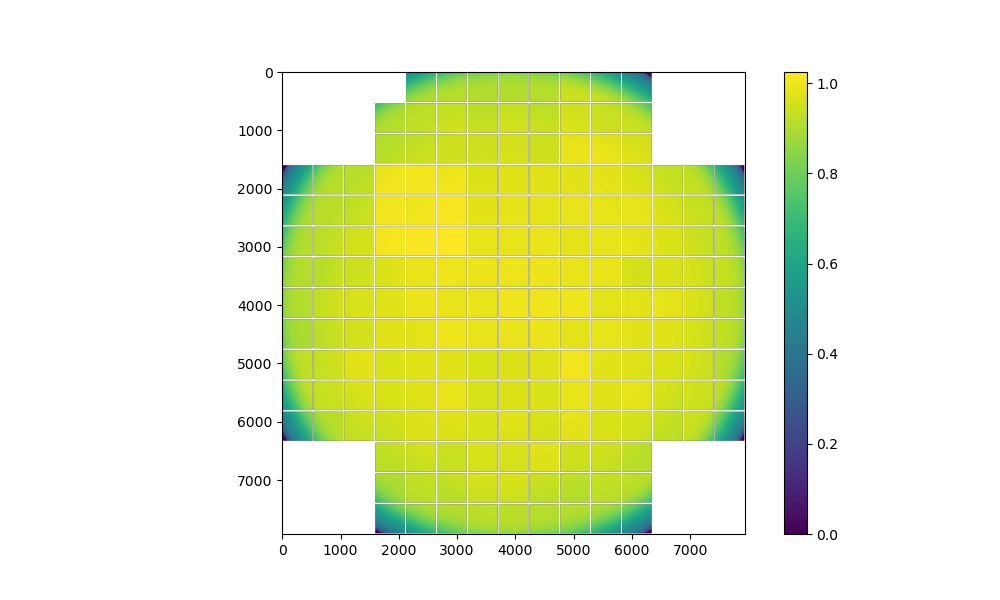

In [8]:
%matplotlib widget

figure=plt.figure(figsize=(10,6))

# _=splot.plot(pIsrMosaic.array, stretch='ccs',cmap='inferno', figure=figure)
plt.imshow(pIsrMosaic.array) #, vmin=np.nanpercentile(pIsrMosaic.array,5), vmax=np.nanpercentile(pIsrMosaic.array,99),cmap='gray', origin='lower')
plt.colorbar()
# plt.imshow(ppIsrMosaic.array, vmin=np.nanpercentile(ppIsrMosaic.array,5), vmax=np.nanpercentile(ppIsrMosaic.array,95),alpha=0.75)
# _=splot.plot(ppIsrMosaic.array, stretch='ccs',cmap='inferno', figure=figure)
ax=figure.axes[0]
# ax.set_title(f'{exp}, sep {sep} - pos {pos}')


# valid_rows = np.where(~np.isnan(pIsrMosaic.array).all(axis=1))[0]
# valid_cols = np.where(~np.isnan(pIsrMosaic.array).all(axis=0))[0]

# # Extract boundaries
# row_min, row_max = valid_rows[0], valid_rows[-1]
# col_min, col_max = valid_cols[0], valid_cols[-1]




# ax.set_xlim(col_min-50,col_max+50)
# ax.set_ylim(row_min-50,row_max+50)
# plt.savefig(f'{exp}-pred.png',dpi=400)
plt.show()

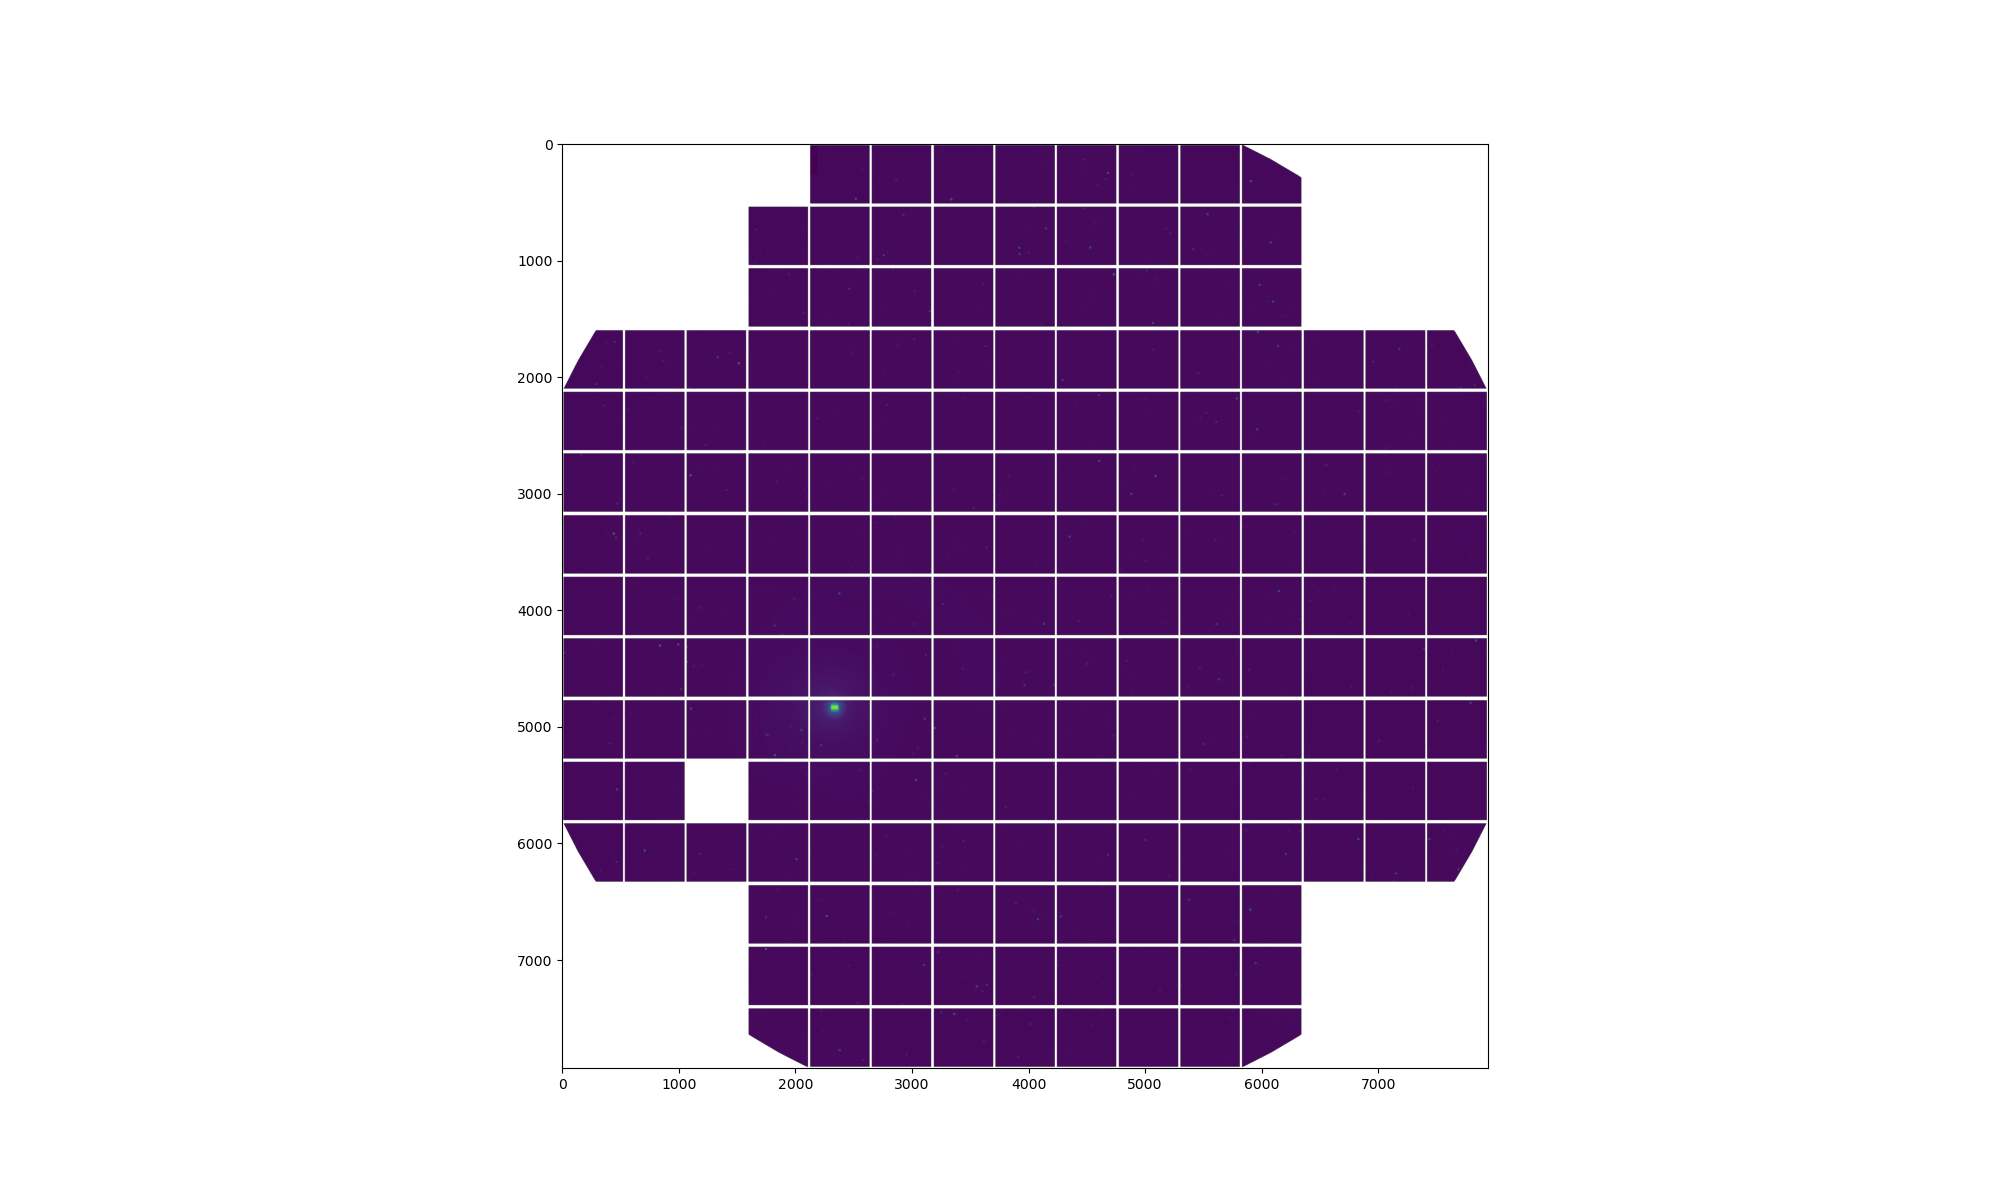

In [18]:
%matplotlib widget

figure=plt.figure(figsize=(20,12))

# _=splot.plot(-pIsrMosaic.array, stretch='ccs',cmap='inferno', figure=figure)
plt.imshow(pIsrMosaic.array)

In [132]:
# plt.hist(-pIsrMosaic.array.flatten().reshape(-1,1),bins=40)

data=-pIsrMosaic.array

import numpy as np
from scipy.ndimage import sobel

gx = sobel(data, axis=1)
gy = sobel(data, axis=0)
grad_mag = np.hypot(gx, gy)
threshold=1
edge_mask = grad_mag > threshold
from skimage.measure import label, regionprops

labels = label(edge_mask)
min_pixels=300**2
for r in regionprops(labels):
    if r.area > min_pixels:
        print("Candidato step trovato")
print(r.eccentricity)
# plt.imshow(edge_mask,origin='lower')

Candidato step trovato
Candidato step trovato
1.0


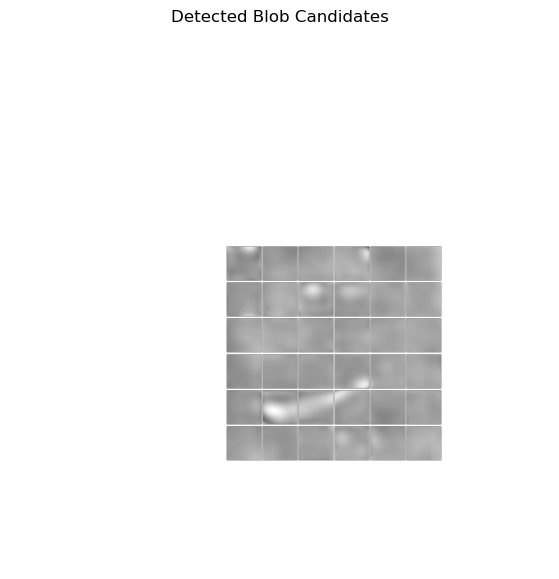

In [24]:
I=-pIsrMosaic.array


import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, gaussian_filter
from skimage.measure import label, regionprops
from skimage.morphology import dilation, disk
from skimage.segmentation import find_boundaries


def detect_blobs_log(
    I,
    sigma_min=2,
    sigma_max=12,
    num_scales=6,
    threshold_factor=1.5,
    min_blob_area=350**2
):
    """
    Detect wide uniform blobs using multiscale Laplacian of Gaussian.
    """

    I_smooth = gaussian_filter(I, 1.0)

    sigmas = np.linspace(sigma_min, sigma_max, num_scales)

    responses = []

    # --- Multiscale LoG ---
    for sigma in sigmas:
        log_resp = -gaussian_laplace(I_smooth, sigma=sigma)
        responses.append(log_resp * sigma**2)  # scale normalization

    response_stack = np.stack(responses, axis=0)

    # Maximum response across scales
    max_response = np.max(response_stack, axis=0)

    # Threshold
    threshold = threshold_factor * np.std(max_response)
    blob_mask = max_response > threshold

    # Connected components
    labels = label(blob_mask)
    final_mask = np.zeros_like(blob_mask)

    for region in regionprops(labels):
        if region.area >= min_blob_area:
            final_mask[region.coords[:,0], region.coords[:,1]] = True

    final_mask = dilation(final_mask, footprint=disk(2))

    return final_mask, max_response


# ======================================================
# =================== ESEMPIO ===========================
# ======================================================

if __name__ == "__main__":
    I=-pIsrMosaic.array

    blob_mask, response = detect_blobs_log(I)

    # --- Plot ---
    plt.figure(figsize=(7,7))
    plt.imshow(I, cmap='gray')

    contours = find_boundaries(blob_mask, mode='outer')
    plt.contour(contours, levels=[0.5])

    plt.title("Detected Blob Candidates")
    plt.axis('off')
    plt.show()


/tmp/ipykernel_17/3990042999.py:41: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  if region.major_axis_length < min_major_axis:


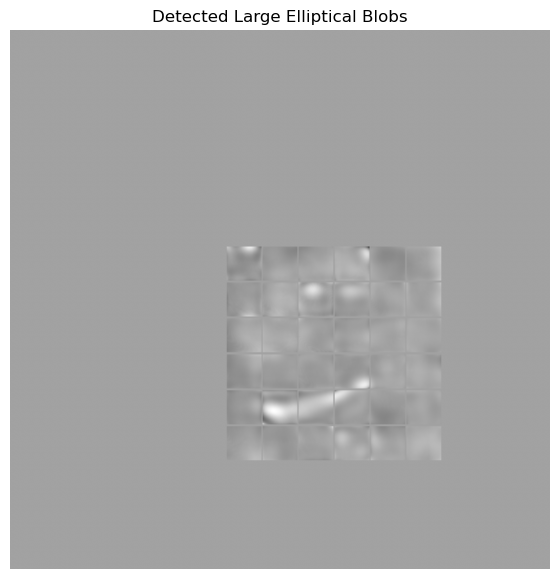

In [26]:
I=-pIsrMosaic.array
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.measure import label, regionprops
from skimage.morphology import remove_small_objects, dilation, disk
from skimage.filters import threshold_otsu
from skimage.segmentation import find_boundaries


def detect_large_elliptical_blobs(
    I,
    smoothing_sigma=4,
    min_area=500,
    min_major_axis=40000,
    min_eccentricity=0.5
):
    """
    Detect large elongated elliptical blobs.
    """

    # --- 1. Smooth image ---
    I_smooth = gaussian_filter(I, sigma=smoothing_sigma)

    # --- 2. Global threshold (robusto) ---
    thresh = threshold_otsu(I_smooth)
    binary = I_smooth > thresh

    # --- 3. Remove small objects ---
    binary = remove_small_objects(binary, max_size=min_area - 1)

    # --- 4. Label connected components ---
    labels = label(binary)
    final_mask = np.zeros_like(binary)

    for region in regionprops(labels):

        if region.area < min_area:
            continue

        if region.major_axis_length < min_major_axis:
            continue

        if region.eccentricity < min_eccentricity:
            continue

        final_mask[region.coords[:,0], region.coords[:,1]] = True

    # Slight dilation for contour visibility
    final_mask = dilation(final_mask, footprint=disk(2))

    return final_mask


# =====================================================
# =================== ESEMPIO ==========================
# =====================================================

if __name__ == "__main__":
    I=-pIsrMosaic.array
    I = np.nan_to_num(I, nan=np.nanmedian(I))

    blob_mask = detect_large_elliptical_blobs(I)

    plt.figure(figsize=(7,7))
    plt.imshow(I, cmap='gray')

    contours = find_boundaries(blob_mask, mode='outer')
    plt.contour(contours, levels=[0.5])

    plt.title("Detected Large Elliptical Blobs")
    plt.axis('off')
    plt.show()


In [ ]:
plt.close('all')
import numpy as np
from scipy.interpolate import griddata

import numpy as np
from scipy.ndimage import label
from scipy.interpolate import griddata
import numpy as np
from scipy.ndimage import distance_transform_edt

import numpy as np
from scipy.ndimage import distance_transform_edt
from scipy.interpolate import griddata

def fill_nan_within_distance(arr, max_distance=20, method="cubic"):
    filled = arr.copy()
    nan_mask = np.isnan(arr)

    # Distance to nearest valid point
    dist = distance_transform_edt(nan_mask)

    # Only fill NaNs close enough to real values
    fill_mask = nan_mask & (dist <= max_distance)

    if not np.any(fill_mask):
        return filled  # nothing to fill

    x, y = np.indices(arr.shape)
    valid = ~nan_mask

    interp_vals = griddata(
        (x[valid], y[valid]),
        arr[valid],
        (x[fill_mask], y[fill_mask]),
        method=method
    )

    filled[fill_mask] = interp_vals
    return filled



plot_mosaic_with_contours(fill_nan_within_distance(pIsrMosaic.array),exp)
# print(pIsrMosaic.array.mean)

In [ ]:
exp=2026010900079
coll=['u/elhoward/StrayLight/diffim',"LSSTCam/runs/nightlyValidation","u/ataranto/lsst_outputs","u/rosignol/straylight/visit-mosaic","u/ataranto/banana"]  #can also be a list of multiple collections
repo='main'
butler = Butler(repo, collections=coll)

where_clause = f"instrument='LSSTCam' and visit={exp}"

tot_tr_ref=butler.query_datasets('single_visit_star_ref_match_photom_photoDiffCModelScatterVisitPlot_ScatterPlotWithTwoHists', where=where_clause)[0]
tract_img=butler.getURI(tot_tr_ref).read()
from IPython.display import Image
Image(tract_img)
# single_visit_star_ref_match_photom_photoDiffPsfScatterVisitPlot_ScatterPlotWithTwoHists find out how to do this plot from a private catalog


In [ ]:
exp=2026010900079
coll=['u/elhoward/StrayLight/diffim',"LSSTCam/runs/nightlyValidation","u/ataranto/lsst_outputs","u/rosignol/straylight/visit-mosaic","u/ataranto/banana"]  #can also be a list of multiple collections
repo='main'
butler = Butler(repo, collections=coll)

for k in range(0,4):
    tot_tr_ref=butler.query_datasets('single_visit_psf_star', where=where_clause)[0]
    s_vis_met=butler.get(tot_tr_ref)
    for i in range(len(s_vis_met[0])):
        print(s_vis_met.keys()[i],s_vis_met[k][i])
    print('------------------------')


In [57]:
exp=2026010900079
coll=['u/elhoward/StrayLight/diffim',"LSSTCam/runs/nightlyValidation","u/ataranto/lsst_outputs","u/rosignol/straylight/visit-mosaic","u/ataranto/banana"]  #can also be a list of multiple collections
repo='main'
butler = Butler(repo, collections=coll)
registry=butler.registry
Dref = list(registry.queryDatasets('post_isr_image', where=f"visit={exp}"))
# print(Dref)
exposures = [ butler.get(dr) for dr in Dref]
# print(exposures)


In [ ]:
plt.close('all')
for ex in exposures:
    img=ex.image.array.flatten().reshape(-1,1)
    img=img[img < np.nanpercentile(img, 99)]
    # plt.title(f'{exp} det {ex.getDetector().getId()}')
    # plt.hist(img, bins=40)
    # plt.axvline(np.nanmean(img), ls='--', color='r')
    # plt.xlim(1450,1900)
    # plt.show()
    # print(np.nanmean(img),np.nanmedian(img))

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Load or create float image
# ---------------------------
# Replace this with your real image load
# Example: image = np.load("image.npy")
image =exposures[10].image.array # np.random.rand(4000, 4000).astype(np.float32)

# ---------------------------
# Configuration
# ---------------------------
tiles_per_axis = 30       # 5x5 grid = 25 histograms
num_bins = 256          # histogram resolution

height, width = image.shape
tile_h = height // tiles_per_axis
tile_w = width // tiles_per_axis

superpx = []

# ---------------------------
# Compute histograms per tile
# ---------------------------
for row in range(tiles_per_axis):
    for col in range(tiles_per_axis):
        y0 = row * tile_h
        y1 = (row + 1) * tile_h
        x0 = col * tile_w
        x1 = (col + 1) * tile_w
        
        tile = image[y0:y1, x0:x1]
        tile = tile[tile < np.nanpercentile(tile,99)]
        superpx.append(tile)
# plt.title("Histogram of Tile 0")
# plt.hist(superpx[2].flatten().reshape(-1,1),bins=50)
# plt.xlabel("Bin Index")
# plt.ylabel("Pixel Count")
# plt.show()
print(exposures[10].getDetector().getId())
for i in range(len(superpx)):
    print(np.mean(superpx[i]))

Processing visit 2025121900041...


  3%|▎         | 6/189 [00:00<00:09, 18.86it/s]/opt/lsst/software/stack/conda/envs/lsst-scipipe-10.1.0-exact/share/eups/Linux64/obs_base/gdab83eb0e6+5b1a939f4f/python/lsst/obs/base/formatters/fitsExposure.py:787: FutureWarning: Summary fields [starEMedian, starUnNormalizedEMedian] not recognized by this software version; ignoring them.
  result = self.reader.read(**self.checked_parameters)
100%|██████████| 189/189 [04:22<00:00,  1.39s/it]


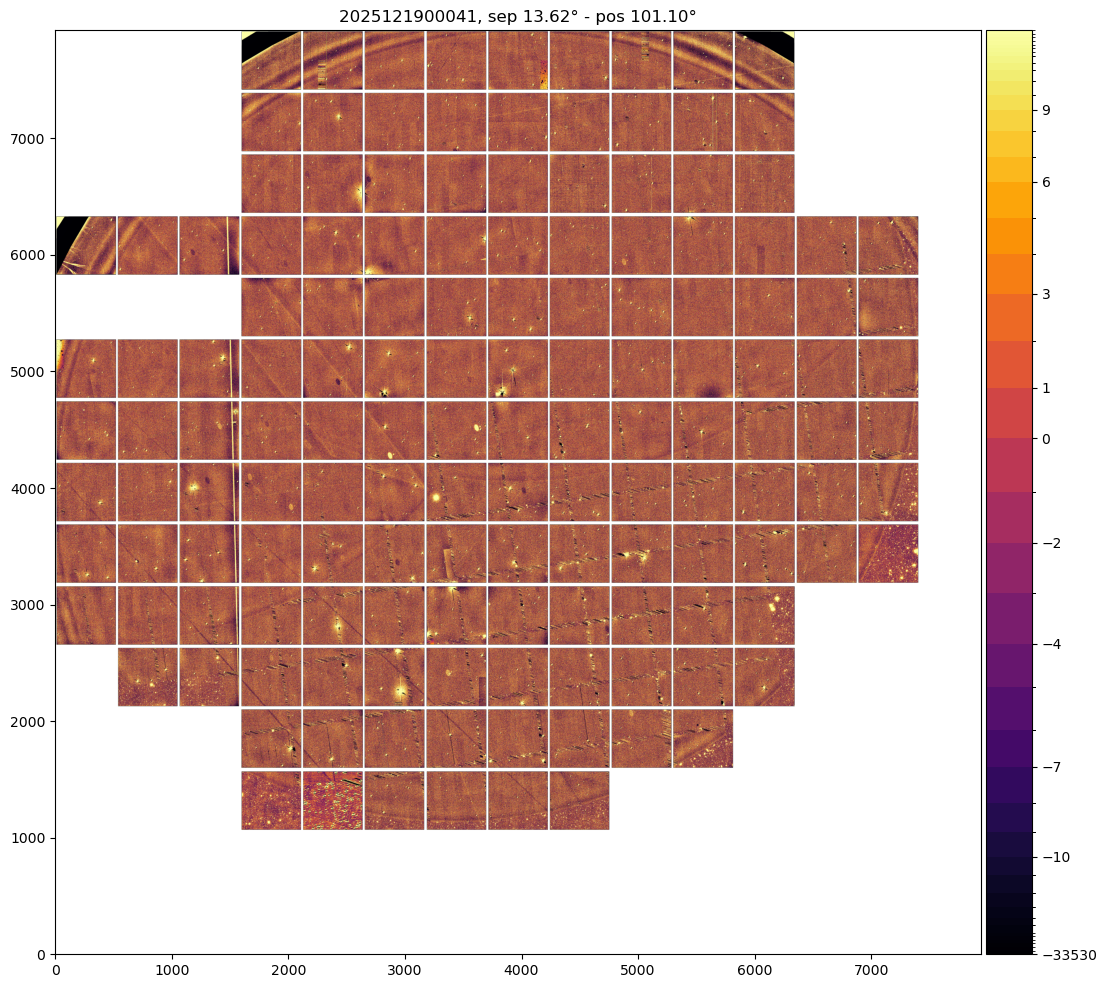

Processing visit 2025121900042...


  2%|▏         | 3/189 [00:00<00:08, 20.89it/s]/opt/lsst/software/stack/conda/envs/lsst-scipipe-10.1.0-exact/share/eups/Linux64/obs_base/gdab83eb0e6+5b1a939f4f/python/lsst/obs/base/formatters/fitsExposure.py:787: FutureWarning: Summary fields [starEMedian, starUnNormalizedEMedian] not recognized by this software version; ignoring them.
  result = self.reader.read(**self.checked_parameters)
 42%|████▏     | 79/189 [01:52<03:38,  1.99s/it]

In [ ]:
butler = Butler("main", collections=['u/ataranto/StrayLight/diffim'], instrument="LSSTCam")
visit_list=range( 2025121900041, 2025121900080)
detects=range(0,189)
binning=8
pIsrImsBinned=[]
ids=[]
for visit in (visit_list):
    print(f"Processing visit {visit}...")
    t = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()
    ra = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
    dec = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()
    info=butler.get('raw.visitInfo', detector=94, exposure=visit)  #change exposure to visit for raw or post_isr
    st_time=str(info.date).split('"')[1]
    center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')

    sat = gu.get_obj_position(t.mjd,'SATURN BARYCENTER')
    satDistance = center.separation(sat).deg
    sat_ha = gu.get_pos_ang(sat, center, "rubin", t)
    for i in tqdm(detects):
        dataId = {"instrument": "LSSTCam", "visit":visit , "detector": i}
        try:
            im = butler.get("difference_image_predetection", dataId=dataId)
        except:
            continue
            
        ids.append(i)
        pIsrImsBinned.append(binImage(im.getImage(), binning))       #by default this makes a mean bining, 

    camera = getCameraFromInstrumentName('LSSTCam')
    plt.close('all')
    mosConfig = VisualizeMosaicExpConfig()
    mosConfig.binning = binning
    mosTask = VisualizeMosaicExpTask(config=mosConfig)
    
    pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
        
    figure=plt.figure(figsize=(20,12))
    
    _=splot.plot(pIsrMosaic.array, stretch='ccs',cmap='inferno', figure=figure)
    ax=figure.axes[0]
    ax.set_title(f'{visit}, sep {satDistance:.2f}° - pos {sat_ha.value*180/np.pi:.2f}°')
    plt.savefig(f'{visit}_diffim.png')
    plt.show()

In [19]:
print(1e5)

100000.0
